In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

In [ ]:
df = pd.read_csv('/content/Iris.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nClass Distribution:")
print(df['Species'].value_counts())

Dataset Shape: (150, 6)

First 5 rows:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa



Class Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [ ]:
X = df.drop(['Id', 'Species'], axis=1)
y = df['Species']

feature_names = X.columns.tolist()
class_names = y.unique().tolist()

print("Features:", feature_names)
print("Classes:", class_names)

Features: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")

Training samples: 105
Testing samples:  45


In [ ]:
clf = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    min_samples_split=2,
    random_state=42
)

clf.fit(X_train, y_train)
print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [ ]:
y_pred = clf.predict(X_test)
print("Predictions completed.")

Predictions completed.


In [ ]:
print("="*50)
print("MODEL EVALUATION")
print("="*50)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report (Precision, Recall, F1-score):")
print(classification_report(y_test, y_pred, target_names=class_names))

MODEL EVALUATION
Accuracy: 0.9778

Classification Report (Precision, Recall, F1-score):
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      0.93      0.97        15
 Iris-virginica       0.94      1.00      0.97        15

       accuracy                           0.98        45
      macro avg       0.98      0.98      0.98        45
   weighted avg       0.98      0.98      0.98        45



In [ ]:
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, average=None, labels=class_names
)

print("Per-class Metrics:")
for i, cls in enumerate(class_names):
    print(f"{cls:20} | Precision: {precision[i]:.3f} | Recall: {recall[i]:.3f} | F1: {f1[i]:.3f}")

Per-class Metrics:
Iris-setosa          | Precision: 1.000 | Recall: 1.000 | F1: 1.000
Iris-versicolor      | Precision: 1.000 | Recall: 0.933 | F1: 0.966
Iris-virginica       | Precision: 0.938 | Recall: 1.000 | F1: 0.968


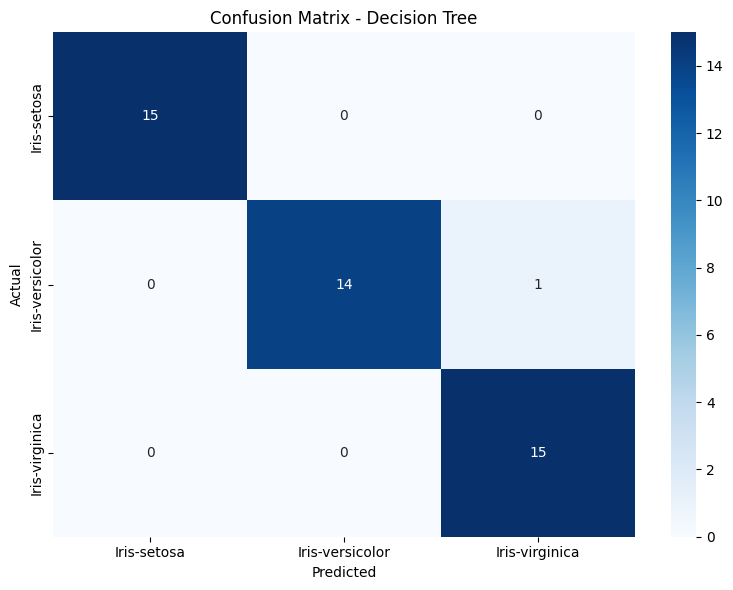

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=class_names)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Decision Tree')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

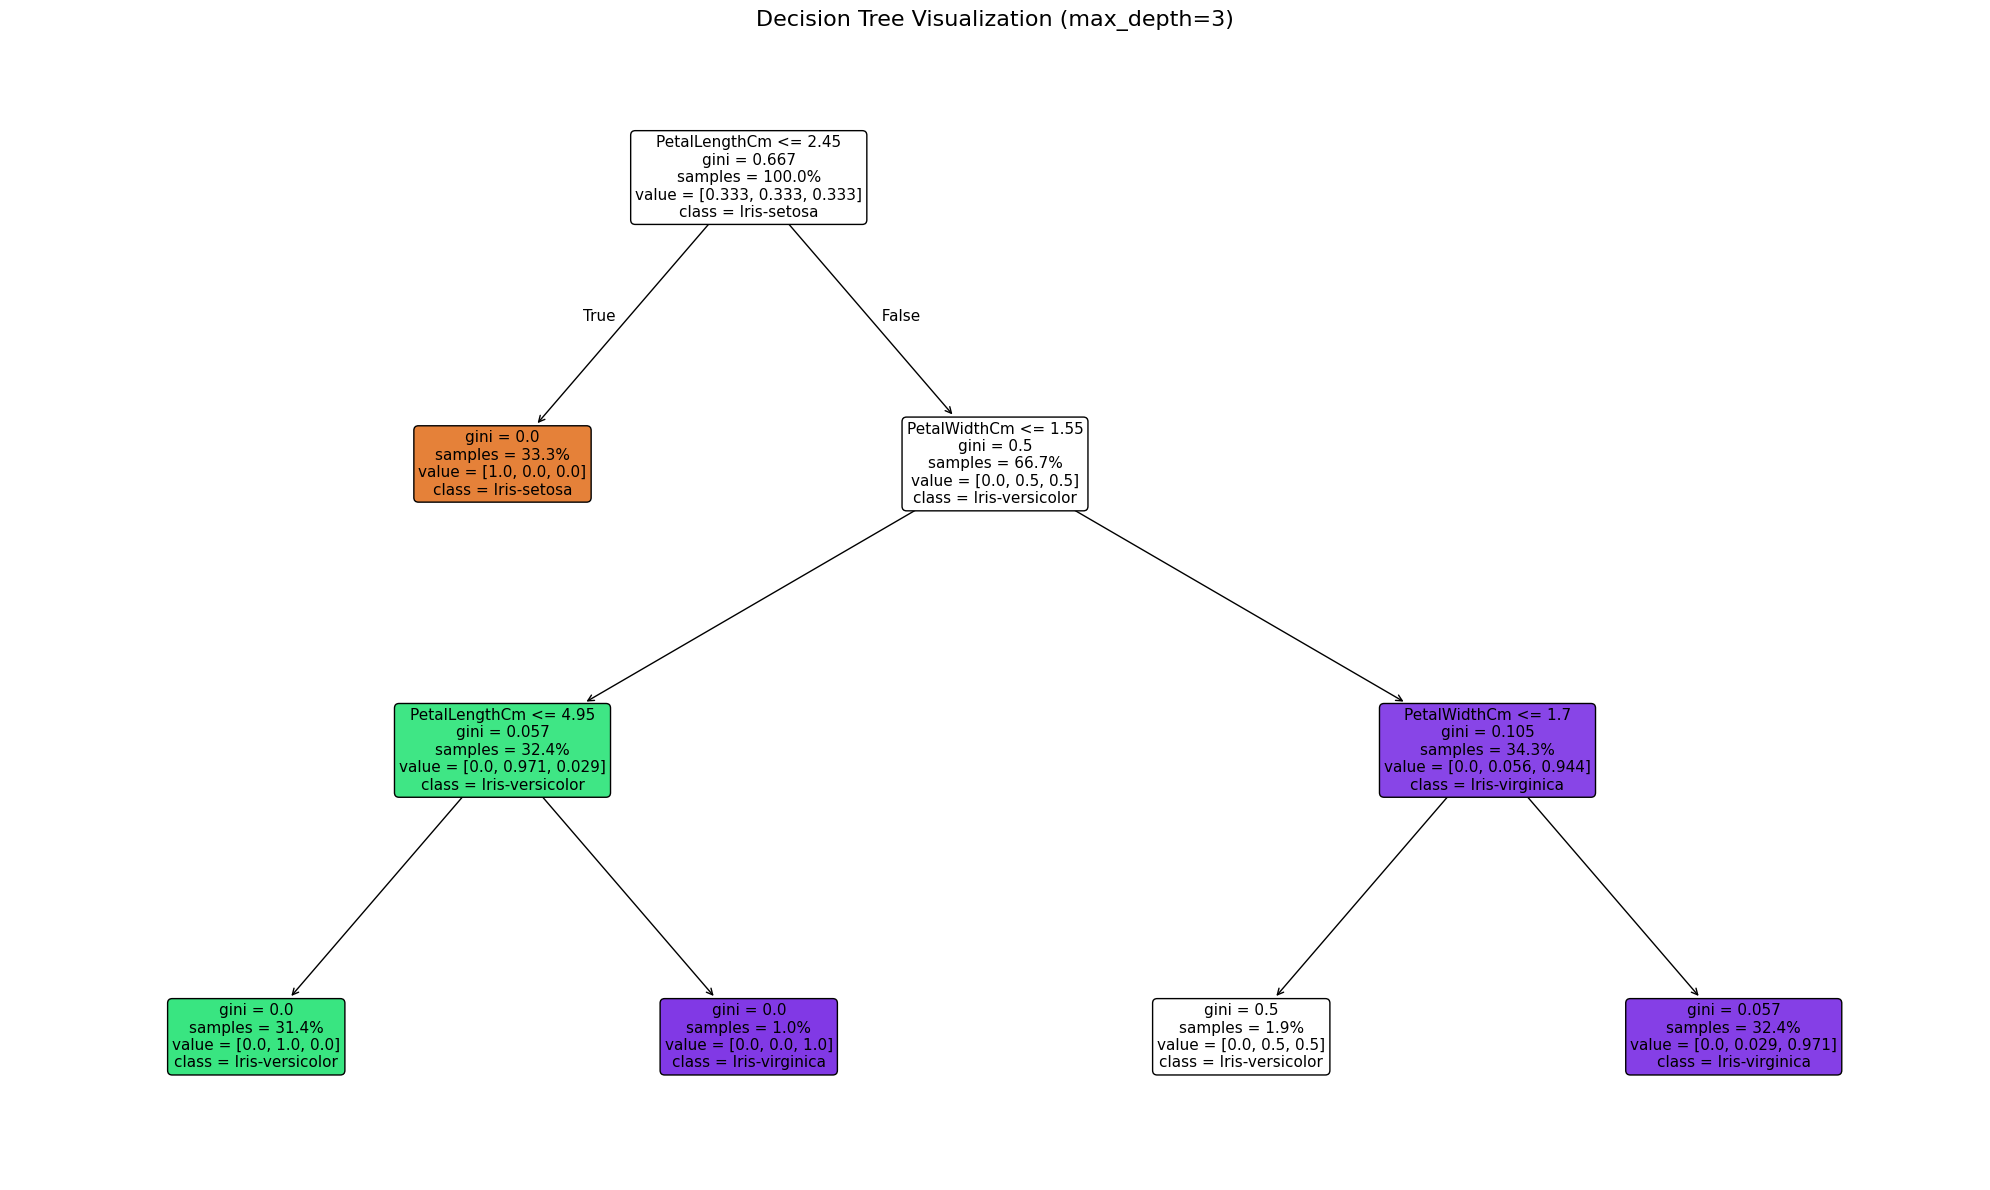

In [ ]:
plt.figure(figsize=(20, 12))
plot_tree(
    clf,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=11,
    proportion=True
)
plt.title('Decision Tree Visualization (max_depth=3)', fontsize=16)
plt.tight_layout()
plt.show()

Feature Importances:


,Feature,Importance
2,PetalLengthCm,0.550877
3,PetalWidthCm,0.449123
1,SepalWidthCm,0.000000
0,SepalLengthCm,0.000000


/tmp/ipykernel_1715/3397664419.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')


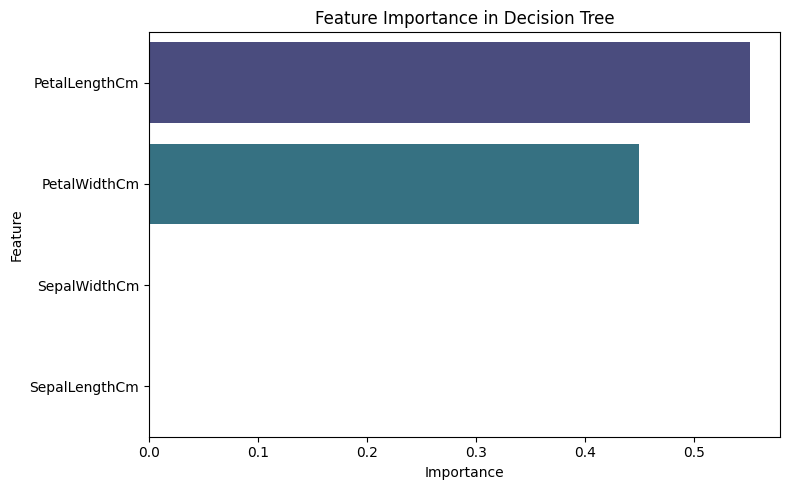

In [ ]:
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': clf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Feature Importances:")
display(importance_df)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance in Decision Tree')
plt.tight_layout()
plt.show()